# 07 — Business Insights & Risk Tiering

**Input:** `models/best_model.pkl`, `models/optimal_threshold.pkl`, `data/processed/features.csv`, `data/processed/clean.csv`  
**Outputs:** `outputs/asset_risk_scores.csv`, `outputs/maintenance_priority_list.csv`, `outputs/regional_risk_breakdown.png`

### Steps covered
1. Score all 50,000 assets
2. Assign risk tiers (HIGH / MEDIUM / LOW)
3. Build maintenance priority list
4. Risk-impact prioritization score
5. Regional and asset-type breakdown
6. Financial impact quantification
7. Save outputs

In [1]:
import pandas as pd
import numpy as np
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

os.makedirs('../outputs', exist_ok=True)
print('Libraries loaded.')

Libraries loaded.


## Step 1 — Score All 50,000 Assets

We score the **entire dataset** (not just the test set) to produce an actionable priority list for all grid assets.

In [2]:
df_features = pd.read_csv('../data/processed/features.csv')
df_clean    = pd.read_csv('../data/processed/clean.csv')

y_all = df_features['grid_failure_flag']
X_all = df_features.drop(columns=['grid_failure_flag'])

with open('../models/best_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('../models/optimal_threshold.pkl', 'rb') as f:
    OPTIMAL_THRESHOLD = pickle.load(f)

failure_probs = model.predict_proba(X_all)[:, 1]

print(f'Model: {type(model).__name__}')
print(f'Threshold: {OPTIMAL_THRESHOLD:.4f}')
print(f'Assets scored: {len(failure_probs):,}')
print(f'Failure probability — min: {failure_probs.min():.4f}  max: {failure_probs.max():.4f}  mean: {failure_probs.mean():.4f}')

Model: LGBMClassifier
Threshold: 0.4652
Assets scored: 50,000
Failure probability — min: 0.0019  max: 0.9999  mean: 0.4470


## Step 2 — Assign Risk Tiers

| Tier | Threshold | Action |
|------|-----------|--------|
| **HIGH** | prob ≥ 0.70 | Immediate intervention — schedule within next maintenance window |
| **MEDIUM** | 0.45 ≤ prob < 0.70 | Schedule within next quarter — monitor closely |
| **LOW** | prob < 0.45 | Routine maintenance schedule — standard monitoring |

In [3]:
def assign_risk_tier(prob):
    if prob >= 0.70:   return 'HIGH'
    elif prob >= 0.45: return 'MEDIUM'
    else:              return 'LOW'

# Build results dataframe
context_cols = ['asset_type', 'substation_region', 'manufacturer', 'asset_age_years',
                'equipment_health_score', 'maintenance_overdue_days',
                'customers_served', 'estimated_revenue_loss',
                'regulatory_penalty_cost', 'grid_failure_flag']

results = df_clean[context_cols].copy()
results['failure_probability'] = failure_probs
results['predicted_failure']   = (failure_probs >= OPTIMAL_THRESHOLD).astype(int)
results['risk_tier']           = results['failure_probability'].apply(assign_risk_tier)

tier_counts = results['risk_tier'].value_counts()
print('Risk Tier Distribution:')
print(tier_counts)
print(f'\nHIGH risk:   {tier_counts.get("HIGH", 0):,} assets ({tier_counts.get("HIGH",0)/len(results)*100:.1f}%)')
print(f'MEDIUM risk: {tier_counts.get("MEDIUM", 0):,} assets ({tier_counts.get("MEDIUM",0)/len(results)*100:.1f}%)')
print(f'LOW risk:    {tier_counts.get("LOW", 0):,} assets ({tier_counts.get("LOW",0)/len(results)*100:.1f}%)')

Risk Tier Distribution:
risk_tier
LOW       26755
HIGH      15715
MEDIUM     7530
Name: count, dtype: int64

HIGH risk:   15,715 assets (31.4%)
MEDIUM risk: 7,530 assets (15.1%)
LOW risk:    26,755 assets (53.5%)


## Step 3 — Maintenance Priority List

In [4]:
priority_cols = ['asset_type', 'substation_region', 'manufacturer', 'asset_age_years',
                 'equipment_health_score', 'maintenance_overdue_days',
                 'customers_served', 'estimated_revenue_loss',
                 'failure_probability', 'risk_tier']

high_risk = (
    results[results['risk_tier'] == 'HIGH'][priority_cols]
    .sort_values('failure_probability', ascending=False)
    .reset_index(drop=True)
)
high_risk.index += 1
high_risk.index.name = 'priority_rank'

print(f'Top 20 Highest-Risk Assets:')
print(high_risk.head(20)[['asset_type', 'substation_region', 'asset_age_years',
                           'equipment_health_score', 'maintenance_overdue_days',
                           'failure_probability']].to_string())

Top 20 Highest-Risk Assets:
                      asset_type substation_region  asset_age_years  equipment_health_score  maintenance_overdue_days  failure_probability
priority_rank                                                                                                                             
1                    Transformer           Central                3               35.111541                       149             0.999887
2              Transmission Line             South               25               35.640294                       158             0.999787
3                     Substation             South               38               30.979945                       138             0.999765
4              Transmission Line             South               33                1.639653                       170             0.999764
5                     Substation           Central                6               32.964013                       175             0.999760

## Step 4 — Risk-Impact Score

Multiplies failure probability by normalized business impact (customers + revenue) to rank assets by **expected harm**, not just probability.

In [5]:
scaler = MinMaxScaler()
results['norm_customers']    = scaler.fit_transform(results[['customers_served']])
results['norm_revenue_loss'] = scaler.fit_transform(results[['estimated_revenue_loss']])
results['impact_score']      = (results['norm_customers'] + results['norm_revenue_loss']) / 2
results['risk_impact_score'] = results['failure_probability'] * results['impact_score']

top_impact = results.nlargest(10, 'risk_impact_score')[
    ['asset_type', 'substation_region', 'failure_probability',
     'customers_served', 'estimated_revenue_loss', 'risk_impact_score']
]
print('Top 10 Assets by Risk-Impact Score (probability × business impact):')
print(top_impact.round(4).to_string())

Top 10 Assets by Risk-Impact Score (probability × business impact):
              asset_type substation_region  failure_probability  customers_served  estimated_revenue_loss  risk_impact_score
16903  Transmission Line              East               0.8573             96020              50000000.0             0.8402
49207         Substation             South               0.9986             65615              50000000.0             0.8267
10762    Circuit Breaker              East               0.8310             97410              50000000.0             0.8203
3584         Transformer           Central               0.9120             79817              50000000.0             0.8199
35489        Transformer             North               0.9935             63593              50000000.0             0.8125
9478          Substation           Central               0.8746             84970              50000000.0             0.8088
9659          Substation              East               

## Step 5 — Regional & Asset-Type Breakdown

In [6]:
region_summary = results.groupby('substation_region').agg(
    total_assets        = ('failure_probability', 'count'),
    high_risk_assets    = ('risk_tier', lambda x: (x == 'HIGH').sum()),
    avg_failure_prob    = ('failure_probability', 'mean'),
    total_revenue_at_risk = ('estimated_revenue_loss',
                              lambda x: results.loc[x.index[results.loc[x.index, 'risk_tier'] == 'HIGH'],
                                                     'estimated_revenue_loss'].sum())
).sort_values('high_risk_assets', ascending=False)
region_summary['revenue_at_risk_M'] = region_summary['total_revenue_at_risk'] / 1e6
region_summary['high_risk_pct'] = (region_summary['high_risk_assets'] / region_summary['total_assets'] * 100).round(1)
print('Regional Risk Summary:')
print(region_summary[['total_assets','high_risk_assets','high_risk_pct','avg_failure_prob','revenue_at_risk_M']].round(3))

type_summary = results.groupby('asset_type').agg(
    total_assets     = ('failure_probability', 'count'),
    high_risk_count  = ('risk_tier', lambda x: (x == 'HIGH').sum()),
    avg_failure_prob = ('failure_probability', 'mean')
).sort_values('avg_failure_prob', ascending=False)
print('\nAsset Type Risk Summary:')
print(type_summary.round(3))

Regional Risk Summary:
                   total_assets  high_risk_assets  high_risk_pct  \
substation_region                                                  
East                      10134              3248           32.1   
South                     10008              3138           31.4   
North                      9970              3118           31.3   
Central                    9978              3111           31.2   
West                       9910              3100           31.3   

                   avg_failure_prob  revenue_at_risk_M  
substation_region                                       
East                          0.451           2324.803  
South                         0.446           1764.710  
North                         0.450           1776.089  
Central                       0.441           1892.622  
West                          0.446           1862.726  

Asset Type Risk Summary:
                   total_assets  high_risk_count  avg_failure_prob
asset_ty

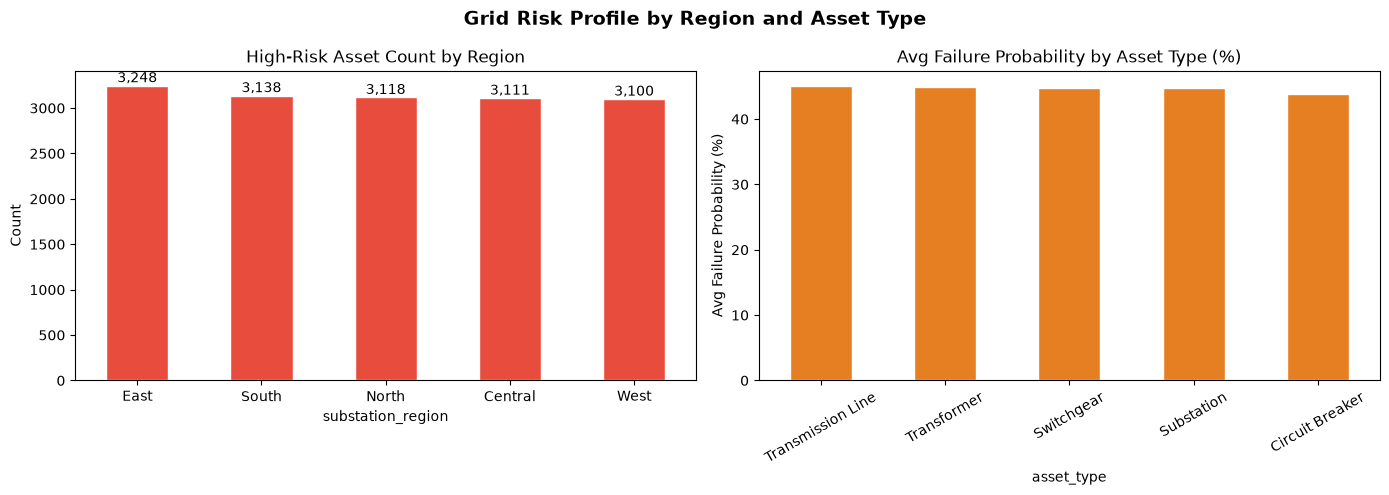

Saved: outputs/regional_risk_breakdown.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# High-risk count by region
region_summary['high_risk_assets'].plot(
    kind='bar', ax=axes[0], color='#e74c3c', edgecolor='white'
)
axes[0].set_title('High-Risk Asset Count by Region', fontsize=12)
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=10)

# Avg failure probability by asset type
type_summary['avg_failure_prob'].mul(100).plot(
    kind='bar', ax=axes[1], color='#e67e22', edgecolor='white'
)
axes[1].set_title('Avg Failure Probability by Asset Type (%)', fontsize=12)
axes[1].set_ylabel('Avg Failure Probability (%)')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Grid Risk Profile by Region and Asset Type', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/regional_risk_breakdown.png', dpi=150)
plt.show()
print('Saved: outputs/regional_risk_breakdown.png')

## Step 6 — Financial Impact Quantification

Using industry benchmark: predictive maintenance reduces unplanned outages by **15–30%**  
(Source: Duke Energy, Enel, National Grid deployment reports — cited in pre-submission document).

In [8]:
high_risk_df = results[results['risk_tier'] == 'HIGH']

total_revenue_at_risk  = high_risk_df['estimated_revenue_loss'].sum()
total_penalty_at_risk  = high_risk_df['regulatory_penalty_cost'].sum()
total_exposure         = total_revenue_at_risk + total_penalty_at_risk
inspection_cost        = len(high_risk_df) * 1_500  # ~$1,500 per inspection

conservative_saving = total_exposure * 0.15
optimistic_saving   = total_exposure * 0.30

print('=== Financial Impact Analysis ===')
print(f'HIGH risk assets identified:       {len(high_risk_df):>8,}')
print(f'Revenue at risk:                   ${total_revenue_at_risk:>15,.0f}')
print(f'Regulatory penalties at risk:      ${total_penalty_at_risk:>15,.0f}')
print(f'Total financial exposure:          ${total_exposure:>15,.0f}')
print()
print(f'Cost to inspect all HIGH-risk:     ${inspection_cost:>15,.0f}')
print()
print(f'Savings (conservative 15%):        ${conservative_saving:>15,.0f}')
print(f'Savings (optimistic 30%):          ${optimistic_saving:>15,.0f}')
print()
print(f'Net benefit (conservative):        ${conservative_saving - inspection_cost:>15,.0f}')
print(f'Net benefit (optimistic):          ${optimistic_saving - inspection_cost:>15,.0f}')
print(f'\nROI (conservative):                {(conservative_saving / inspection_cost):.1f}x')
print(f'ROI (optimistic):                  {(optimistic_saving / inspection_cost):.1f}x')

=== Financial Impact Analysis ===
HIGH risk assets identified:         15,715
Revenue at risk:                   $  9,620,948,613
Regulatory penalties at risk:      $  3,949,207,621
Total financial exposure:          $ 13,570,156,234

Cost to inspect all HIGH-risk:     $     23,572,500

Savings (conservative 15%):        $  2,035,523,435
Savings (optimistic 30%):          $  4,071,046,870

Net benefit (conservative):        $  2,011,950,935
Net benefit (optimistic):          $  4,047,474,370

ROI (conservative):                86.4x
ROI (optimistic):                  172.7x


## Step 7 — Save Outputs

In [9]:
# Full scored dataset
results.to_csv('../outputs/asset_risk_scores.csv', index=False)
print(f'Saved: outputs/asset_risk_scores.csv  ({len(results):,} assets)')

# HIGH-risk priority list
high_risk.to_csv('../outputs/maintenance_priority_list.csv')
print(f'Saved: outputs/maintenance_priority_list.csv  ({len(high_risk):,} HIGH-risk assets)')

print('\n=== Story 07 Complete ===')
print(f'Total assets scored:  {len(results):,}')
print(f'HIGH risk:            {tier_counts.get("HIGH",0):,}')
print(f'MEDIUM risk:          {tier_counts.get("MEDIUM",0):,}')
print(f'LOW risk:             {tier_counts.get("LOW",0):,}')

Saved: outputs/asset_risk_scores.csv  (50,000 assets)
Saved: outputs/maintenance_priority_list.csv  (15,715 HIGH-risk assets)

=== Story 07 Complete ===
Total assets scored:  50,000
HIGH risk:            15,715
MEDIUM risk:          7,530
LOW risk:             26,755
